# Lost & Found: Logistic Regression base model

**AI Application: Classification. Algorithm/Approach: Logistic Regression.**

The application will compare one lost report with possible found reports and suggest pairs for human review. A score never proves ownership. This notebook uses **real Delhi Metro found-item records** for exploration, then makes **synthetic lost claims** and **constructed pair labels** for an academic model exercise. The measured score below is *not* accuracy on real lost-and-found claims.

Data path: real found CSV → cleaned found rows → synthetic lost claims → constructed pairs → comparison features → Logistic Regression → grouped validation. The raw CSV is local and ignored by Git because descriptions may contain personal information. See `docs/dataset_sources.md` for its source and hash.

## 1. Imports and paths

In [5]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from scripts.prepare_delhi_data import ROOT, SOURCE, OUTPUT, prepare
from scripts.create_delhi_experiment import build, CLAIMS, PAIRS, FEATURES, SPLIT
from matching_system.ml_model import run_experiment

FIGURES = ROOT / 'results/figures'
FIGURES.mkdir(parents=True, exist_ok=True)
print('Raw CSV available:', SOURCE.is_file())

ModuleNotFoundError: No module named 'matplotlib'

## 2. Inspect the untouched real dataset

The Delhi CSV contains found-item records, not lost claims or confirmed matches. We inspect its schema and display only non-sensitive columns. `station_name` is the recorded station associated with receiving the item; it is **not proven to be the exact place the item was lost**.

In [4]:
raw = pd.read_csv(SOURCE, dtype=str)
print('Raw shape:', raw.shape)
print('Original columns:', raw.columns.tolist())
display(raw[['item_name', 'station_name', 'receiving_date']].head())
print('Missing by field:')
display(raw.isna().sum().to_frame('missing_rows'))
print('Exact duplicate rows:', int(raw.duplicated().sum()))

NameError: name 'pd' is not defined

## 3. Clean and audit the real found items

We keep the six original fields and every source row. The cleaning code collapses repeated whitespace, adds separate casefolded text columns, parses dates and times to ISO format, and counts missing values and parsing failures. It audits station-name variation before and after whitespace cleanup, but applies no semantic station alias mapping: nearby or similarly named stations are not assumed equivalent. It does not invent colour, location, or descriptions. We keep absent values empty rather than replacing them with false details. No exact duplicates were found, so none are removed.

In [3]:
print('Original date parse failures:', int(pd.to_datetime(raw['receiving_date'], format='%d/%m/%Y', errors='coerce').isna().sum()))
print('Original station whitespace variants:', int((raw['station_name'] != raw['station_name'].str.strip()).sum()))
audit = prepare()
clean = pd.read_csv(OUTPUT, dtype=str)
print('Rows before → after:', len(raw), '→', len(clean))
print('Columns before → after:', len(raw.columns), '→', len(clean.columns))
print('Duplicates identified / removed:', audit['duplicates_identified'], '/', audit['duplicates_removed'])
print('Whitespace changes by field:', audit['whitespace_modified_rows_by_field'])
print('Date/time parsing failures:', audit['parsing_failures'])
print('Station-name audit:', audit['station_name_audit'])
display(clean[['source_row', 'item_name', 'station_name', 'receiving_date_iso']].head())
display(clean.isna().sum().to_frame('missing_after_cleaning'))

Original date parse failures: 0
Original station whitespace variants: 0


Rows before → after: 13713 → 13713
Columns before → after: 6 → 12
Duplicates identified / removed: 0 / 0
Whitespace changes by field: {'station_name': 44, 'description': 77, 'item_name': 161}
Date/time parsing failures: {}
Station-name audit: {'non_empty_rows': 13713, 'distinct_source_values': 229, 'distinct_whitespace_normalized_values': 229, 'distinct_casefolded_values': 229, 'rows_changed_by_whitespace': 44, 'whitespace_collision_groups': 0, 'casefold_collision_groups': 0, 'semantic_alias_mapping_applied': False}


,source_row,item_name,station_name,receiving_date_iso
0,1,CHAIN,VAISHALI,2024-03-21
1,2,EARBUDS CASE,BRIG. HOSHIAR SINGH,2024-03-20
2,3,CARRY BAG,RITHALA,2024-03-20
3,4,BAG,KAROL BAGH,2024-03-20
4,5,JACKET,YASHOBHOOMI DWARKA SECTOR - 25,2024-03-20


,missing_after_cleaning
source_row,0
item_name,0
description,8208
item_quantity,10511
station_name,0
receiving_date,0
receiving_time,0
item_name_normalized,0
description_normalized,8208
station_name_normalized,0


## 4. Four EDA observations from real found-item records

1. The source has **13,713 rows**, and all are retained after cleaning. This is a substantial *found-item* collection, not 13,713 labelled matches.
2. **8,208 descriptions** and **10,511 quantities** are absent. A matching model cannot rely on either field being present.
3. Item names are unevenly distributed: bags, purses, and bottles appear often. A model checked only on frequent categories may miss rarer belongings.
4. Station strings are audited conservatively: whitespace variants are measured and collapsed, while similarly named stations are not merged without record-level evidence. Receiving dates also vary. Location and time can help rank candidates, but a receiving station or date need not equal where or when an item was lost.

The cells calculate each observation and save four aggregate charts. No item descriptions appear in the charts.

In [4]:
missing = raw.isna().sum().sort_values(ascending=False)
items = clean.item_name_normalized.value_counts().head(10)
stations = clean.station_name_normalized.value_counts().head(10)
monthly = pd.to_datetime(clean.receiving_date_iso).dt.to_period('M').value_counts().sort_index()
station_audit = audit['station_name_audit']
print('Total rows:', len(clean), 'distinct item names:', clean.item_name_normalized.nunique())
print('Station strings before whitespace cleanup → after cleanup → casefolded:', station_audit['distinct_source_values'], '→', station_audit['distinct_whitespace_normalized_values'], '→', station_audit['distinct_casefolded_values'])
print('Station collision groups (whitespace / casefold):', station_audit['whitespace_collision_groups'], '/', station_audit['casefold_collision_groups'])
print('Top item names:')
display(items.to_frame('records'))
print('Top stations:')
display(stations.to_frame('records'))
print('Monthly periods:', len(monthly), 'range:', str(monthly.index.min()), 'to', str(monthly.index.max()))

Total rows: 13713 distinct item names: 2895
Station strings before whitespace cleanup → after cleanup → casefolded: 229 → 229 → 229
Station collision groups (whitespace / casefold): 0 / 0
Top item names:


,records
item_name_normalized,
bag,1559
purse,758
bottle,705
lunch box,546
cash,519
poly bag,495
watch,436
helmet,380
umbrella,360


Top stations:


,records
station_name_normalized,
kashmere gate,702
new delhi (yellow & airport line),701
rajiv chowk,630
airport (t-3),587
samaypur badli,475
dwarka sector - 21,466
rithala,334
millennium city centre gurugram,326
chandni chowk,283


Monthly periods: 28 range: 2021-12 to 2024-03


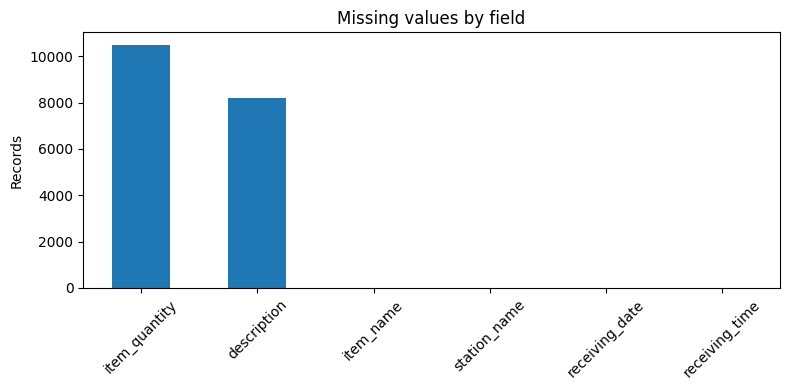

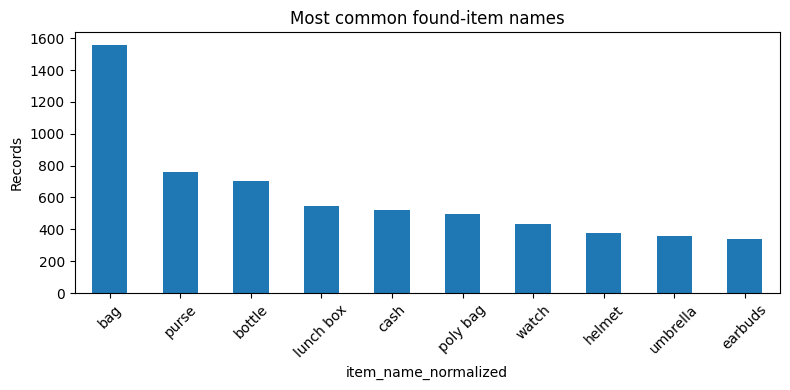

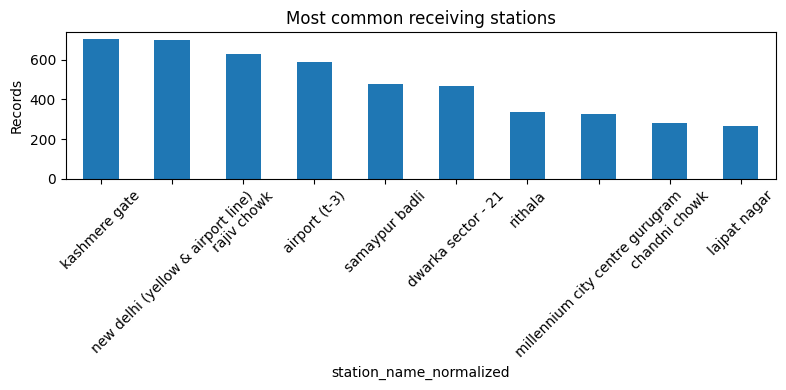

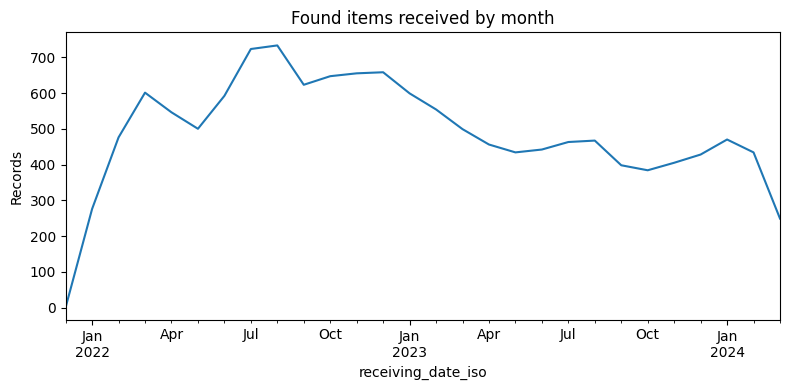

In [5]:
for title, series, filename in [
    ('Missing values by field', missing, 'delhi_missing.png'),
    ('Most common found-item names', items, 'delhi_item_names.png'),
    ('Most common receiving stations', stations, 'delhi_stations.png'),
    ('Found items received by month', monthly, 'delhi_monthly.png'),
]:
    ax = series.plot(kind='line' if filename == 'delhi_monthly.png' else 'bar', figsize=(8, 4), title=title)
    ax.set_ylabel('Records')
    if filename != 'delhi_monthly.png':
        ax.tick_params(axis='x', labelrotation=45)
    plt.tight_layout()
    plt.savefig(FIGURES / filename, dpi=130)
    plt.show()
    plt.close()

## 5. Create synthetic lost claims and constructed pairs

We deterministically select 120 source found rows across ten frequent item names. Each row creates one fictional lost claim. For each claim we pair its source found row (constructed positive), a different row with the same item name (difficult assumed negative), and a row with another item name (assumed negative). **Different rows are not verified different physical objects.** All claims and labels are synthetic; none were submitted by Delhi Metro passengers or Strathmore students. The script uses seed 42 and never edits the raw CSV. It leaves colour blank because the source has no colour field.

In [6]:
summary = build()
claims = pd.read_csv(CLAIMS)
pairs = pd.read_csv(PAIRS)
table = pd.read_csv(FEATURES)
print(summary)
print('Claim fields:', claims.columns.tolist())
print('Pair label bases:')
display(pairs.label_basis.value_counts().to_frame('pairs'))
display(claims[['report_id', 'report_type', 'item_name', 'category', 'location', 'date', 'data_origin']].head())

{'real_found_rows': 13713, 'synthetic_lost_claims': 120, 'constructed_positive_pairs': 120, 'assumed_negative_pairs': 240, 'development_pairs': 252, 'test_pairs': 108}
Claim fields: ['report_id', 'report_type', 'item_name', 'category', 'description', 'colour', 'location', 'date', 'source_found_row', 'data_origin']
Pair label bases:


,pairs
label_basis,
constructed_positive,120
assumed_same_name_negative,120
assumed_other_name_negative,120


,report_id,report_type,item_name,category,location,date,data_origin
0,synthetic-delhi-01034,lost,Bag,Bag,TILAK NAGAR,2024-01-08,synthetic_claim_from_real_found_row
1,synthetic-delhi-02326,lost,Bag,Bag,LAJPAT NAGAR,2023-10-05,synthetic_claim_from_real_found_row
2,synthetic-delhi-03573,lost,Bag,Bag,NEW DELHI (Yellow & Airport Line),2023-07-07,synthetic_claim_from_real_found_row
3,synthetic-delhi-10091,lost,Bag,Bag,MILLENNIUM CITY CENTRE GURUGRAM,2022-07-28,synthetic_claim_from_real_found_row
4,synthetic-delhi-03566,lost,Bag,Bag,KASHMERE GATE,2023-07-08,synthetic_claim_from_real_found_row


## 6. Prepare features and the base model

Each row in `delhi_modelling_pairs.csv` compares one synthetic lost claim and one real found record. **X** contains numeric comparison features; **y** is the constructed match label. Description-word overlap, item-name agreement, station-word overlap and date difference are examples. The helper also has optional colour/brand/model fields; they remain missing for Delhi and do not create false contradictions. Logistic Regression learns feature weights and returns a probability used to rank candidates. Location helps but is never a hard filter.

In [7]:
feature_names = [name for name in table.columns if name not in {'lost_report_id', 'found_report_id', 'original_label', 'target'}]
X = table[feature_names]
y = table.target
print('X shape:', X.shape, 'y counts:', y.value_counts().to_dict())
display(table[['lost_report_id', 'found_report_id', 'description_similarity', 'category_match', 'location_similarity', 'time_difference_hours', 'target']].head())

X shape: (360, 14) y counts: {0: 240, 1: 120}


,lost_report_id,found_report_id,description_similarity,category_match,location_similarity,time_difference_hours,target
0,synthetic-delhi-01034,delhi-01034,0.200000,1,1.0,0.0,1
1,synthetic-delhi-01034,delhi-01054,0.125000,1,0.0,24.0,0
2,synthetic-delhi-01034,delhi-05874,0.200000,0,0.0,48.0,0
3,synthetic-delhi-02326,delhi-02326,0.111111,1,1.0,0.0,1
4,synthetic-delhi-02326,delhi-02586,0.100000,1,0.0,48.0,0


In [8]:
import json
from matching_system.ml_model import new_classifier

development_ids = set(json.loads(SPLIT.read_text())['splits']['development']['lost_ids'])
development = table[table.lost_report_id.isin(development_ids)]
base_model = new_classifier()
base_model.fit(development[feature_names], development.target)
print('Fitted Logistic Regression on', len(development), 'development pairs.')

Fitted Logistic Regression on 252 development pairs.


## 7. Validate and evaluate

All three candidates for one synthetic claim stay in the same split. Each found row is used once, so no found row crosses splits. The scaler fits only training data inside each fold. We use grouped cross-validation on development data and one held-out test set. These checks detect coding or split problems, but **cannot establish performance on real claims**, because positives were created from source rows and negatives were assumed.

In [9]:
result = run_experiment(FEATURES, SPLIT, ROOT / 'results/delhi_experiment')
print('Split:', result['split'])
print('Grouped folds:', len(result['grouped_cv']))
display(pd.DataFrame(result['grouped_cv'])[['fold', 'train_pairs', 'validation_pairs', 'precision', 'recall', 'f1']])
print('Constructed held-out set:', result['held_out_test'])

Split: {'development_pairs': 252, 'test_pairs': 108, 'development_lost_reports': 84, 'test_lost_reports': 36}
Grouped folds: 5


,fold,train_pairs,validation_pairs,precision,recall,f1
0,1,201,51,1.000000,1.000000,1.000000
1,2,201,51,0.882353,0.882353,0.882353
2,3,201,51,0.933333,0.823529,0.875000
3,4,201,51,1.000000,0.882353,0.937500
4,5,204,48,1.000000,0.875000,0.933333


Constructed held-out set: {'precision': 0.9714285714285714, 'recall': 0.9444444444444444, 'f1': 0.9577464788732394, 'confusion_matrix': [[71, 1], [2, 34]]}


## 8. Example suggestions and limitations

These are model outputs for constructed pairs, shown by report ID to avoid displaying potentially sensitive found-item descriptions. Staff would review suggested pairs and verify ownership using private details. The current Android starter does not call this model.

In [10]:
predictions = pd.read_csv(ROOT / 'results/delhi_experiment/test_predictions.csv')
display(predictions.sort_values('match_probability', ascending=False).head(8))
print('Errors on constructed labels:', int((predictions.target != predictions.predicted_class).sum()))

,lost_report_id,found_report_id,original_label,target,match_probability,predicted_class
30,synthetic-delhi-09357,delhi-09357,match,1,0.999812,1
3,synthetic-delhi-02326,delhi-02326,match,1,0.999808,1
15,synthetic-delhi-08548,delhi-08548,match,1,0.999788,1
0,synthetic-delhi-01034,delhi-01034,match,1,0.999776,1
6,synthetic-delhi-10091,delhi-10091,match,1,0.999776,1
63,synthetic-delhi-03181,delhi-03181,match,1,0.999767,1
93,synthetic-delhi-01077,delhi-01077,match,1,0.999755,1
36,synthetic-delhi-10642,delhi-10642,match,1,0.999716,1


Errors on constructed labels: 3


## 9. Further validation

The next meaningful dataset is a consented set of real lost reports, found reports, and confirmed handovers. Keep unresolved candidate pairs **unknown**, rather than calling them non-matches. Hold out entire physical items or case groups, review labels independently, and compare Logistic Regression with a simple alternative on the same groups and metrics. Check precision, recall, F1, and whether the true found item reaches the top three suggestions. Assess errors by item type and missing description. Photos need separately linked same-physical-item pairs before image matching can be claimed.